In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Load dataset
df = pd.read_csv("creditcard (1).csv")

# Drop only 'Time' column
df = df.drop(['Time'], axis=1)

# Separate features and labels
X = df.drop(['Class'], axis=1)
y = df['Class']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split data
x_train, x_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Train only on normal (non-fraud) data
x_train = x_train[y_train == 0]

In [4]:
encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu')
])

decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(16,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(x_train.shape[1], activation='linear')
])

autoencoder = tf.keras.models.Sequential([encoder, decoder])

# Compile model
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

In [5]:
history = autoencoder.fit(
    x_train, x_train,
    validation_data=(x_test, x_test),
    epochs=5,
    batch_size=128,
    shuffle=True
)

Epoch 1/5
1777/1777 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 0.3015 - val_loss: 0.1687
Epoch 2/5
1777/1777 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.1038 - val_loss: 0.1164
Epoch 3/5
1777/1777 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0764 - val_loss: 0.0988
Epoch 4/5
1777/1777 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0643 - val_loss: 0.0887
Epoch 5/5
1777/1777 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0568 - val_loss: 0.0943


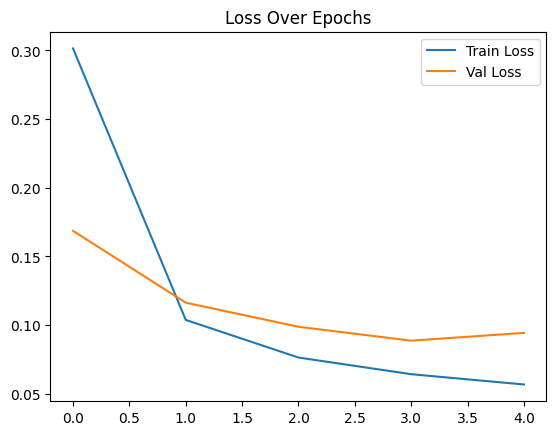

In [6]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss Over Epochs')
plt.show()

In [7]:
# Reconstruction error
predictions = autoencoder.predict(x_test)
mse = np.mean(np.power(x_test - predictions, 2), axis=1)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 986us/step


In [8]:
# Set threshold and detect anomalies
threshold = np.percentile(mse, 95)
anomalies = mse > threshold

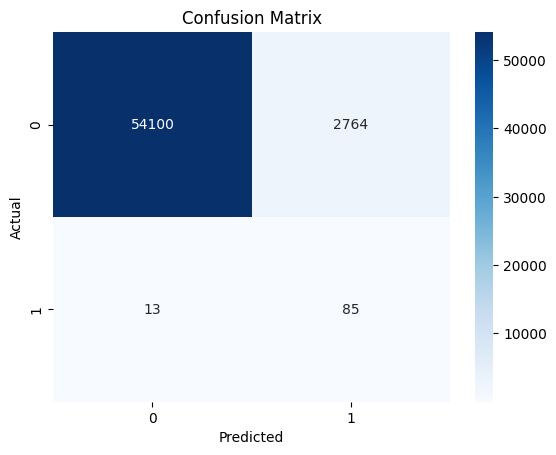

              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.87      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.91      0.52     56962
weighted avg       1.00      0.95      0.97     56962



In [9]:
# Confusion matrix & report
cm = confusion_matrix(y_test, anomalies)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_test, anomalies))